##### Step 5: EDA (Exploratory Data Analysis)

Why: EDA finds patterns, checks assumptions, and answers business questions 1 to 3. Without it you model blindly and can’t explain results to anyone.
If skipped: You miss data problems and weak features, and the report has no insights.

Create a new notebook: notebooks/04_eda.ipynb.

5A. Load

In [1]:
import pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style = "whitegrid")

df = pd.read_csv("../data/processed/eda_table.csv", parse_dates=["order_purchase_timestamp"])
print(df.shape)

(96470, 32)


5B. Target balance

is_late
0    0.918876
1    0.081124
Name: proportion, dtype: float64


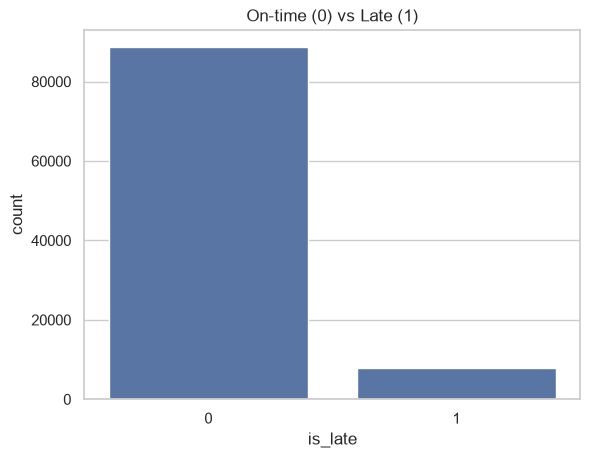

In [2]:
print(df["is_late"].value_counts(normalize=True))
sns.countplot(x="is_late", data=df);
plt.title("On-time (0) vs Late (1)")
plt.savefig("../reports/figures/01_target.png", dpi=150, bbox_inches="tight")

Why: Confirms the 8.1% imbalance that drives our metric choice.

5C. Q1: Revenue by month, category, state

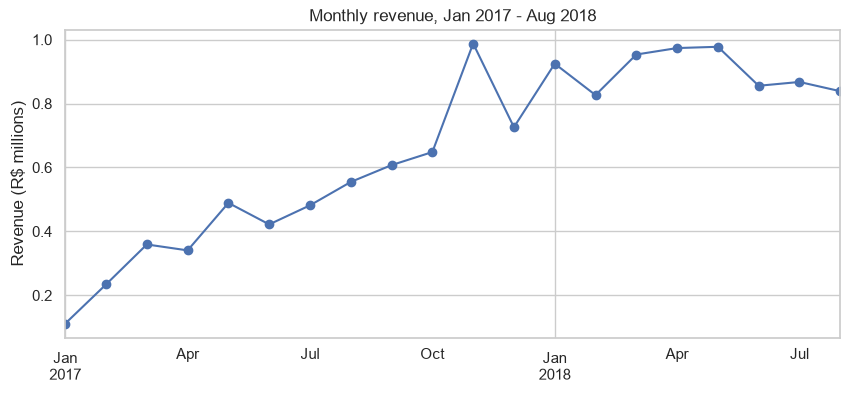

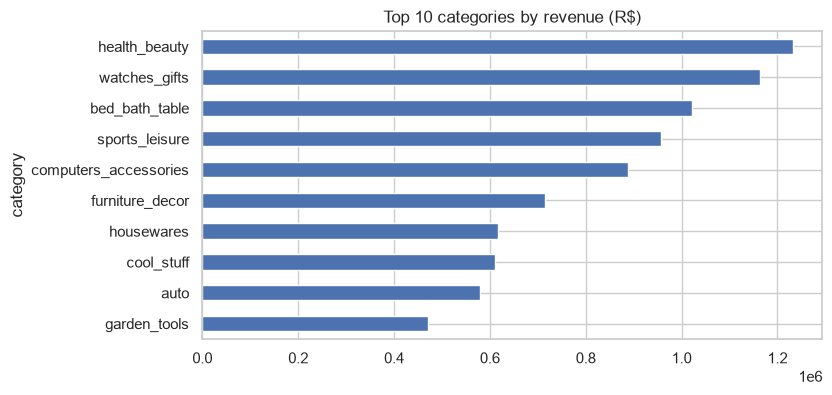

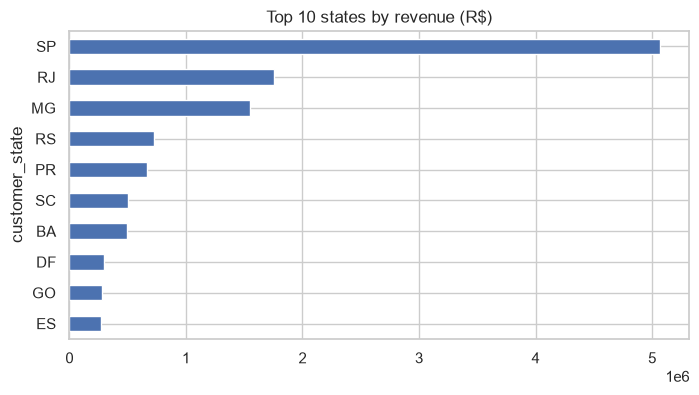

In [3]:
df["month"] = df["order_purchase_timestamp"].dt.to_period("M")
m = df.groupby("month")["total_price"].sum()
m = m["2017-01":"2018-08"] 

fig, ax = plt.subplots(figsize=(10, 4))
(m / 1e6).plot(ax=ax, marker="o")
ax.set_title("Monthly revenue, Jan 2017 - Aug 2018")
ax.set_ylabel("Revenue (R$ millions)")
ax.set_xlabel("")
plt.savefig("../reports/figures/02_monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 4))
df.groupby("category")["total_price"].sum().nlargest(10).sort_values().plot.barh(title="Top 10 categories by revenue (R$)")
plt.show()

plt.figure(figsize=(8, 4))
df.groupby("customer_state")["total_price"].sum().nlargest(10).sort_values().plot.barh(title="Top 10 states by revenue (R$)")
plt.show()

Why we cut months: The dataset starts and ends with partial months, so keeping them draws a fake crash.

5D. Q2: Where do late deliveries happen?

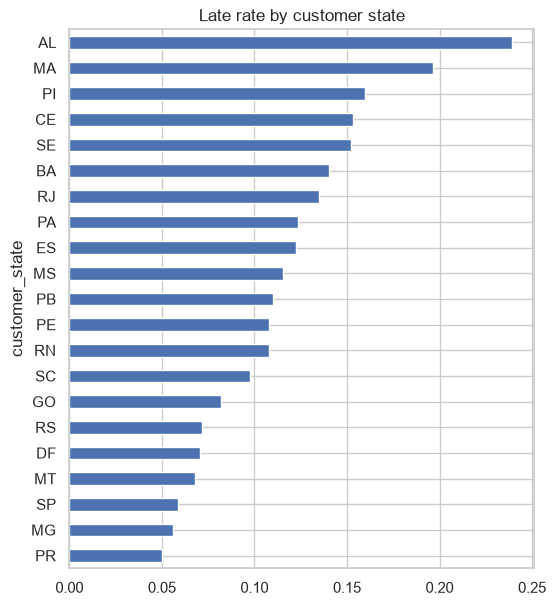

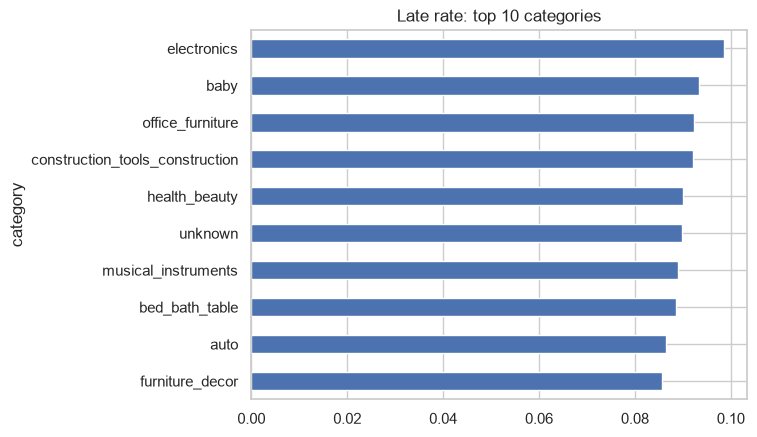

In [4]:
st = df.groupby("customer_state")["is_late"].agg(["mean", "count"])
st[st["count"] > 300]["mean"].sort_values().plot.barh(figsize=(6,7), title="Late rate by customer state")
plt.show()

ct = df.groupby("category")["is_late"].agg(["mean", "count"])
ct[ct["count"] > 500]["mean"].sort_values().tail(10).plot.barh(title="Late rate: top 10 categories")
plt.show()

Why the count filter: A category with 5 orders and 2 late shows 40%, which is noise. Always check sample size before trusting a rate.

5E. Q3: Does lateness hurt reviews?

is_late
0    4.294001
1    2.565331
Name: review_score, dtype: float64


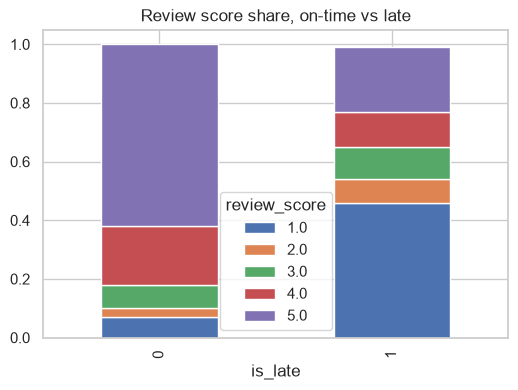

In [5]:
print(df.groupby("is_late")["review_score"].mean())
pd.crosstab(df["is_late"], df["review_score"], normalize="index").round(2).plot.bar(stacked=True, figsize=(6,4))
plt.title("Review score share, on-time vs late"); plt.show()

Note: Review score is for EDA only. It is written after delivery, so using it as a feature would be leakage.

5F. Does distance really matter?

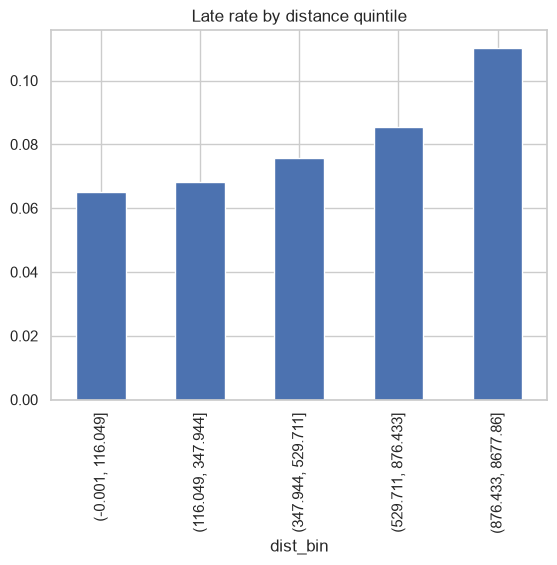

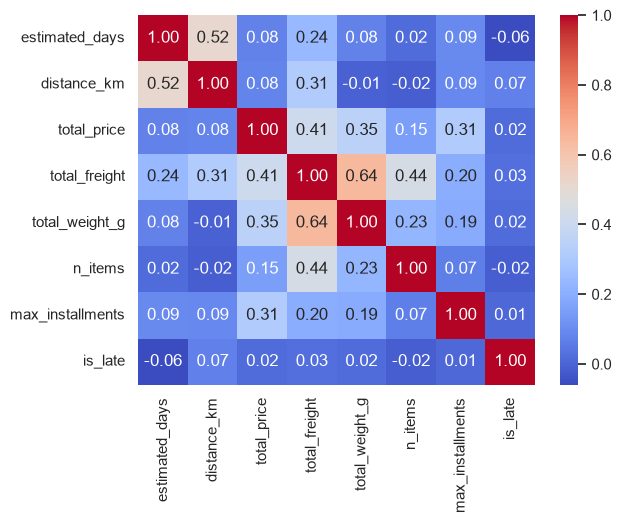

In [6]:
df["dist_bin"] = pd.qcut(df["distance_km"], 5)
df.groupby("dist_bin", observed=True)["is_late"].mean().plot.bar(title="Late rate by distance quintile")
plt.show()

num = ["estimated_days", "distance_km", "total_price", "total_freight", "total_weight_g",
       "n_items", "max_installments", "is_late"]
sns.heatmap(df[num].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.savefig("../reports/figures/03_corr.png", dpi=150, bbox_inches="tight")

Why bins: They show whether late rate rises steadily with distance, which is stronger evidence than two averages.  
Reading correlations: They only catch linear relationships. Tree models find more, so a low value doesn’t mean a useless feature.

5G. Commit

git add .  
git commit -m "Step 5: EDA with business insights"  
git push  